# ECG Identity
### Can a model recognise a person by their heartbeat?

---

This notebook picks up where the signal processing notebook left off. We now ask a machine learning question:

> **If a model learns what one person's heartbeat looks like, can it correctly spot when it sees that person's beat — and reject everyone else's?**

This is called **one-class classification**: the model only ever sees examples of the *right* person during training, then must decide on new beats it has never seen.

We test six models and compare their results side by side:

| Model | Plain-English idea |
|---|---|
| **OC-SVM** | Draws a tight boundary around familiar beats; anything outside is rejected |
| **Isolation Forest** | Spots beats that are unusual by randomly splitting the data many times |
| **LOF** | Checks whether a new beat sits in a dense neighbourhood of known beats |
| **Elliptic Envelope** | Fits a statistical bubble around familiar beats; beats outside the bubble are rejected |
| **MLP Autoencoder** | A neural network that learns to rebuild known beats; beats it rebuilds poorly look suspicious |
| **KAN Autoencoder** | Same rebuild idea, but uses more flexible learned curves — a newer approach |

**How we measure success**

| Score | Meaning | Best value |
|---|---|---|
| **AUROC** | Overall ability to separate the right person from others | 1.0 (0.5 = random) |
| **F1** | Balance between accepting the right person and rejecting impostors | 1.0 |
| **EER** | The point where the miss rate equals the false-alarm rate | 0.0 |

---
## Step 1 — Install & Import Libraries

Install and load everything needed. Only needs to run once.

In [1]:
%pip install --quiet numpy matplotlib scikit-learn pywavelets neurokit2 wfdb torch tqdm pandas seaborn ipywidgets


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pywt
import wfdb
import neurokit2 as nk
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score, roc_curve
from sklearn.decomposition import PCA
from tqdm.auto import tqdm
from matplotlib.patches import Patch

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

print('Libraries loaded.')

Libraries loaded.


---
## Step 2 — Settings

All the numbers that control this notebook are kept here. You can change `NUM_SUBJECTS` to include more people, or adjust `NN_EPOCHS` to train the neural networks longer.

In [3]:
# ── Paths ────────────────────────────────────────────────────
DB_DIR  = './ecgiddb'
OUT_DIR = './ecg_ml_results'
os.makedirs(OUT_DIR, exist_ok=True)

# ── Data settings (must match notebook 1) ───────────────────
NUM_SUBJECTS   = 10
PRE_MS, POST_MS = 250, 450
WAVELET_NAME   = 'morl'
FREQ_MIN, FREQ_MAX, N_FREQS = 1.0, 60.0, 80
N_OCTAVE_BANDS = 5
FS_DEFAULT     = 500

# ── Training settings ────────────────────────────────────────
TRAIN_RATIO = 0.70   # fraction of each person's beats used for training
NN_EPOCHS   = 80     # training epochs for both neural network models

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Running on: {DEVICE}')

Running on: cpu


---
## Step 3 — Prepare the Data

We re-run the same signal processing pipeline from notebook 1, then turn each beat into two compact **feature sets** that the models can work with:

| Feature set | What it contains | Size |
|---|---|---|
| **Raw shape** | The z-scored waveform of the beat | ~350 values |
| **WTMM summary** | Line count, average frequency, and energy per frequency band | 26 values |

Having two feature sets lets us see which representation works better for each model.

In [4]:
# ── Signal processing helpers ────────────────────────────────

def detect_rpeaks(sig, fs):
    """Clean the ECG and return heartbeat peak locations."""
    signals, info = nk.ecg_process(sig, sampling_rate=fs)
    return np.array(info['ECG_R_Peaks']), signals['ECG_Clean'].values


def extract_beats(cleaned, r_idx, fs):
    """Cut one window per heartbeat and return them as a 2D array."""
    pre_s, post_s = PRE_MS / 1000., POST_MS / 1000.
    epochs = nk.epochs_create(cleaned, events=r_idx, sampling_rate=fs,
                               epochs_start=-pre_s, epochs_end=post_s)
    keys  = sorted(epochs.keys(), key=lambda k: int(k))
    beats = np.array([epochs[k]['Signal'].values for k in keys])
    return beats, np.linspace(-pre_s, post_s, beats.shape[1])


def compute_wtmm_lines(power, scales, min_len=2):
    """Find and connect the strongest ridgelines in the time-frequency image."""
    n_scales, n_times = power.shape
    mask = np.zeros_like(power, dtype=bool)
    for s in range(n_scales):
        r = power[s]
        if n_times >= 3:
            mask[s, 1:-1] = (r[1:-1] > r[:-2]) & (r[1:-1] > r[2:])
        if n_times >= 2:
            mask[s, 0]  = r[0] > r[1]
            mask[s, -1] = r[-1] > r[-2]
        else:
            mask[s, 0]  = True
    maxima_idx = [np.where(mask[s])[0].tolist() for s in range(n_scales)]
    used, lines = [set() for _ in range(n_scales)], []
    for s0 in range(n_scales):
        for t0 in maxima_idx[s0]:
            if t0 in used[s0]: continue
            line = [(s0, t0)]; used[s0].add(t0); prev_t = t0
            for s in range(s0 + 1, n_scales):
                tol   = max(1, int(round(scales[s] / 2.0)))
                cands = [tt for tt in maxima_idx[s]
                         if tt not in used[s] and abs(int(tt) - int(prev_t)) <= tol]
                if not cands: break
                nxt = min(cands, key=lambda x: abs(x - prev_t))
                line.append((s, int(nxt))); used[s].add(int(nxt)); prev_t = int(nxt)
            if len(line) >= min_len: lines.append(line)
    return lines


def wtmm_feature_vector(beat, scales, freqs_out, fs):
    """Summarise the line image as 26 numbers a model can work with."""
    coeffs, _ = pywt.cwt(beat, scales, WAVELET_NAME, sampling_period=1./fs)
    power  = np.abs(coeffs) ** 2
    lines  = compute_wtmm_lines(power, scales)
    edges  = np.logspace(np.log10(FREQ_MIN), np.log10(FREQ_MAX), N_OCTAVE_BANDS + 1)
    feats  = [len(lines)]
    for lo, hi in zip(edges[:-1], edges[1:]):
        band = [l for l in lines if any(lo <= freqs_out[si] <= hi for si, _ in l)]
        if band:
            pf = [freqs_out[si] for l in band for si, ti in l if lo <= freqs_out[si] <= hi]
            pp = [power[si, ti]  for l in band for si, ti in l if lo <= freqs_out[si] <= hi]
            feats += [len(band), np.mean(pf), np.std(pf), np.mean(pp), np.std(pp)]
        else:
            feats += [0, 0., 0., 0., 0.]
    return np.array(feats, dtype=np.float32)


print('Helper functions ready.')

Helper functions ready.


In [5]:
if not os.path.exists(DB_DIR):
    print('Downloading ECG-ID database — this may take a few minutes ...')
    wfdb.dl_database('ecgiddb', DB_DIR)
else:
    print('Database already on disk — skipping download.')

cf = pywt.central_frequency(WAVELET_NAME)
subject_feats_raw  = {}
subject_feats_wtmm = {}

for subj_idx in range(NUM_SUBJECTS):
    subj_num = subj_idx + 1
    rec_name = f'{DB_DIR}/Person_{subj_num:02d}/rec_1'
    print(f'\n→ Person {subj_num:02d}', end='  ')
    try:
        rec = wfdb.rdrecord(rec_name)
    except Exception as e:
        print(f'Could not read file: {e}'); continue

    try:    sig = rec.p_signal[:, 0]
    except: sig = np.asarray(rec.p_signal).flatten()
    fs = getattr(rec, 'fs', FS_DEFAULT) or FS_DEFAULT

    r_idx, cleaned = detect_rpeaks(sig, fs)
    beats, _       = extract_beats(cleaned, r_idx, fs)
    print(f'{beats.shape[0]} beats  (sample rate: {fs} Hz)')

    freqs    = np.logspace(np.log10(FREQ_MIN), np.log10(FREQ_MAX), N_FREQS)
    scales   = cf * fs / freqs
    _, f_out = pywt.cwt(beats[0], scales, WAVELET_NAME, sampling_period=1./fs)

    # Raw waveform: z-score normalise each beat
    subject_feats_raw[subj_idx] = np.vstack(
        [((b - b.mean()) / (b.std() + 1e-8)).astype(np.float32) for b in beats])

    # WTMM summary statistics
    subject_feats_wtmm[subj_idx] = np.vstack(
        [wtmm_feature_vector(b, scales, f_out, fs)
         for b in tqdm(beats, desc=f'  WTMM P{subj_num:02d}', leave=False)])

print('\n✓ All people processed.')

Database already on disk — skipping download.

→ Person 01  24 beats  (sample rate: 500 Hz)


  WTMM P01:   0%|          | 0/24 [00:00<?, ?it/s]


→ Person 02  23 beats  (sample rate: 500 Hz)


  WTMM P02:   0%|          | 0/23 [00:00<?, ?it/s]


→ Person 03  25 beats  (sample rate: 500 Hz)


...


→ Person 09  20 beats  (sample rate: 500 Hz)


  WTMM P09:   0%|          | 0/20 [00:00<?, ?it/s]


→ Person 10  28 beats  (sample rate: 500 Hz)


  WTMM P10:   0%|          | 0/28 [00:00<?, ?it/s]


✓ All people processed.


---
## Step 4 — Visualise the Feature Space

Before training any model, it helps to see whether the features naturally separate people. We compress everything down to two dimensions using PCA and plot each person's beats as coloured dots.

If each person's dots form a distinct cluster, the classification task should be easier. Overlapping clusters mean the models will have to work harder.

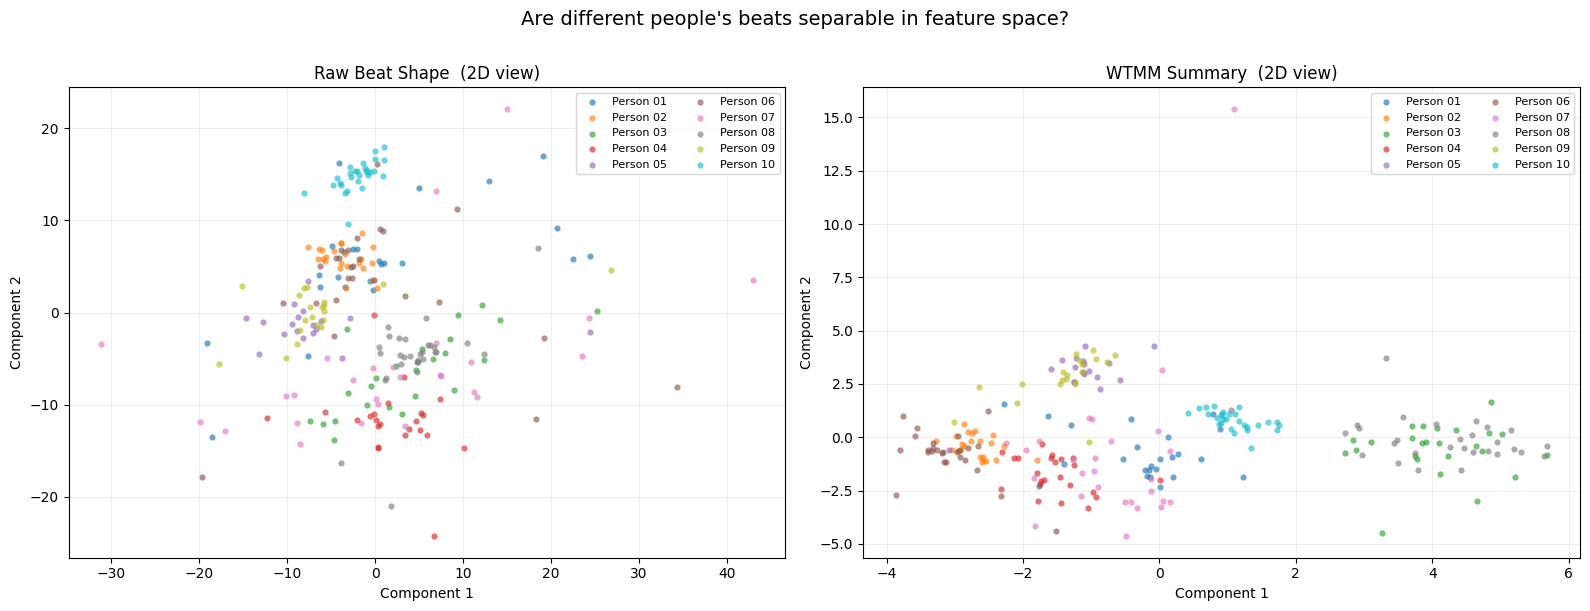

In [6]:
all_raw    = np.vstack([subject_feats_raw[i]  for i in sorted(subject_feats_raw)])
all_wtmm   = np.vstack([subject_feats_wtmm[i] for i in sorted(subject_feats_wtmm)])
all_labels = np.concatenate([np.full(subject_feats_raw[i].shape[0], i)
                              for i in sorted(subject_feats_raw)])

scaler_raw  = StandardScaler().fit(all_raw)
scaler_wtmm = StandardScaler().fit(all_wtmm)
pca_raw  = PCA(n_components=2).fit_transform(scaler_raw.transform(all_raw))
pca_wtmm = PCA(n_components=2).fit_transform(scaler_wtmm.transform(all_wtmm))

palette = plt.cm.get_cmap('tab10', NUM_SUBJECTS)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, pca, title in zip(axes,
        [pca_raw, pca_wtmm],
        ['Raw Beat Shape', 'WTMM Summary']):
    for i in sorted(np.unique(all_labels)):
        m = all_labels == i
        ax.scatter(pca[m, 0], pca[m, 1], color=palette(int(i)),
                   label=f'Person {i+1:02d}', s=20, alpha=0.65, linewidths=0)
    ax.set_title(f'{title}  (2D view)', fontsize=12)
    ax.set_xlabel('Component 1'); ax.set_ylabel('Component 2')
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.2)

plt.suptitle('Are different people\'s beats separable in feature space?', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/feature_space.png', dpi=200, bbox_inches='tight')
plt.show()

---
## Step 5 — Define the Models

### 5a — Traditional Classifiers

These four models use different strategies to define what a "normal" beat looks like for one person, then score how unusual any new beat appears.

In [7]:
def build_traditional_models(n_train):
    # LOF needs fewer neighbours than training samples — we adapt this automatically
    lof_k = max(2, min(20, n_train - 1))
    return {
        'OC-SVM':            OneClassSVM(kernel='rbf', nu=0.1, gamma='scale'),
        'Isolation Forest':  IsolationForest(n_estimators=200, contamination=0.1, random_state=42),
        'LOF':               LocalOutlierFactor(n_neighbors=lof_k, novelty=True, contamination=0.1),
        'Elliptic Envelope': EllipticEnvelope(contamination=0.1, random_state=42),
    }

print('Traditional classifiers ready.')

Traditional classifiers ready.


### 5b — MLP Autoencoder

An autoencoder learns to compress a beat down to a small set of numbers, then reconstruct it back. When trained only on one person's beats, it gets good at rebuilding those — and struggles with everyone else's. The reconstruction error becomes the anomaly score.

In [8]:
class MLPAutoencoder(nn.Module):
    def __init__(self, dim, latent=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(dim, 128), nn.ReLU(),
                                  nn.Linear(128, 64),  nn.ReLU(),
                                  nn.Linear(64, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(),
                                  nn.Linear(64, 128),   nn.ReLU(),
                                  nn.Linear(128, dim))

    def forward(self, x): return self.dec(self.enc(x))

    def recon_error(self, x):
        """Return the average squared difference between input and reconstruction."""
        with torch.no_grad(): return ((self(x) - x) ** 2).mean(1).cpu().numpy()


def train_mlp(X, dim, epochs=NN_EPOCHS, lr=1e-3):
    model  = MLPAutoencoder(dim).to(DEVICE)
    opt    = optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(torch.tensor(X).to(DEVICE)), batch_size=32, shuffle=True)
    model.train()
    for _ in range(epochs):
        for (xb,) in loader:
            opt.zero_grad(); nn.MSELoss()(model(xb), xb).backward(); opt.step()
    return model.eval()


print('MLP Autoencoder ready.')

MLP Autoencoder ready.


### 5c — KAN Autoencoder

This uses the same autoencoder idea but replaces each standard connection with a **learnable B-spline curve**. A B-spline is a smooth, flexible curve controlled by a handful of learned points. Because the shape of every function is learned from data — rather than fixed in advance — the network can potentially fit the structure of ECG beats more precisely with fewer parameters.

This architecture is based on the **Kolmogorov–Arnold Network (KAN)** proposed by Liu et al. (2024).

In [9]:
class BSplineEdge(nn.Module):
    """One KAN layer: each connection uses a learnable B-spline + a residual term."""

    def __init__(self, in_f, out_f, G=5, k=3):
        super().__init__()
        self.in_f, self.G, self.k = in_f, G, k
        n = G + k
        self.sp_w   = nn.Parameter(torch.randn(out_f, in_f, n) * 0.1)
        self.base_w = nn.Parameter(torch.randn(out_f, in_f)    * 0.1)
        h    = 2.0 / G
        grid = torch.arange(-k, G + k + 1) * h - 1.0
        self.register_buffer('grid', grid)

    def bspline(self, x):
        """Evaluate the B-spline basis at each input value."""
        x = x.unsqueeze(-1)
        g = self.grid.view(1, 1, -1)
        b = ((x >= g[:, :, :-1]) & (x < g[:, :, 1:])).float()
        for order in range(1, self.k + 1):
            gl, gr   = g[:, :, :-(order+1)], g[:, :, order:-1]
            gl2, gr2 = g[:, :, 1:-order],    g[:, :, (order+1):]
            d1, d2   = gr - gl, gr2 - gl2
            b1 = torch.where(d1 > 1e-8, (x - gl)  / d1 * b[:, :, :-1], torch.zeros_like(b[:, :, :-1]))
            b2 = torch.where(d2 > 1e-8, (gr2 - x) / d2 * b[:, :,  1:], torch.zeros_like(b[:, :,  1:]))
            b  = b1 + b2
        return b

    def forward(self, x):
        sp = torch.einsum('oin,bin->bo', self.sp_w, self.bspline(x.clamp(-1., 1.)))
        return sp + nn.functional.silu(x) @ self.base_w.T


class KANAutoencoder(nn.Module):
    def __init__(self, dim, latent=12):
        super().__init__()
        self.enc = nn.Sequential(BSplineEdge(dim, 64), BSplineEdge(64, latent))
        self.dec = nn.Sequential(BSplineEdge(latent, 64), BSplineEdge(64, dim))

    def forward(self, x): return self.dec(self.enc(x))

    def recon_error(self, x):
        with torch.no_grad(): return ((self(x) - x) ** 2).mean(1).cpu().numpy()


def train_kan(X, dim, epochs=NN_EPOCHS, lr=3e-4):
    model  = KANAutoencoder(dim).to(DEVICE)
    opt    = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched  = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loader = DataLoader(TensorDataset(torch.tensor(X).to(DEVICE)), batch_size=32, shuffle=True)
    model.train()
    for _ in range(epochs):
        for (xb,) in loader:
            opt.zero_grad(); loss = nn.MSELoss()(model(xb), xb)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sched.step()
    return model.eval()


print('KAN Autoencoder ready.')

KAN Autoencoder ready.


---
## Step 6 — Run the Benchmark

For each person we:
1. Use **70 %** of their beats to train every model (the model only sees this person's beats)
2. Test on the remaining **30 %** mixed with an equal number of beats from all other people
3. Record how well each model separates the right person from everyone else

We do this twice — once with raw waveform features and once with WTMM summary features.

In [10]:
def eer_score(y_true, scores):
    """Equal Error Rate: the point where miss rate equals false-alarm rate."""
    fpr, tpr, _ = roc_curve(y_true, scores)
    fnr = 1 - tpr
    i   = np.nanargmin(np.abs(fnr - fpr))
    return (fpr[i] + fnr[i]) / 2.


def safe_normalise(scores):
    """Scale any score array to [0, 1] without crashing on flat inputs."""
    scores = np.asarray(scores, dtype=float)
    return (scores - scores.min()) / (scores.max() - scores.min() + 1e-12)


def evaluate_subject(subj_idx, feat_key='raw', pca_dim=40, verbose=False):
    feat_dict = subject_feats_raw  if feat_key == 'raw' else subject_feats_wtmm
    scaler    = scaler_raw         if feat_key == 'raw' else scaler_wtmm

    # This person's beats = positive class; all others = negative class
    pos  = scaler.transform(feat_dict[subj_idx])
    negs = np.vstack([scaler.transform(feat_dict[i]) for i in feat_dict if i != subj_idx])

    rng = np.random.default_rng(42 + subj_idx)
    neg = negs[rng.choice(len(negs), size=len(pos), replace=len(negs) < len(pos))]

    n_pos = len(pos)
    if n_pos < 4:
        raise ValueError(f'Person {subj_idx+1:02d} has too few beats ({n_pos}) to evaluate.')

    perm    = rng.permutation(n_pos)
    n_train = min(max(3, int(n_pos * TRAIN_RATIO)), n_pos - 1)

    X_tr  = pos[perm[:n_train]]
    X_pos = pos[perm[n_train:]]
    X_neg = neg

    # PCA compression — adapt component count to avoid errors on small datasets
    if feat_key == 'raw' and pca_dim:
        n_comp = min(int(pca_dim), X_tr.shape[0], X_tr.shape[1])
        if n_comp >= 1 and X_tr.shape[1] > n_comp:
            pca_ = PCA(n_components=n_comp, random_state=42)
            X_tr  = pca_.fit_transform(X_tr)
            X_pos = pca_.transform(X_pos)
            X_neg = pca_.transform(X_neg)
            if verbose: print(f'PCA-{n_comp}', end=' ')

    X_test = np.vstack([X_pos, X_neg])
    y_test = np.array([1] * len(X_pos) + [0] * len(X_neg))
    dim    = X_tr.shape[1]
    results = {}

    # Traditional classifiers
    for name, clf in build_traditional_models(n_train=len(X_tr)).items():
        try:
            clf.fit(X_tr)
            try:   sc = clf.score_samples(X_test); sc_tr = clf.score_samples(X_tr)
            except: sc = clf.decision_function(X_test); sc_tr = clf.decision_function(X_tr)
            norm = safe_normalise(sc)
            thr  = np.median(sc_tr)
            results[name] = dict(auroc=roc_auc_score(y_test, norm),
                                  f1=f1_score(y_test, (sc >= thr).astype(int), zero_division=0),
                                  eer=eer_score(y_test, norm))
        except Exception as e:
            if verbose: print(f'[{name} failed: {type(e).__name__}]', end=' ')
            results[name] = dict(auroc=np.nan, f1=np.nan, eer=np.nan)

    # MLP Autoencoder
    mlp  = train_mlp(X_tr.astype(np.float32), dim)
    Xt   = torch.tensor(X_test.astype(np.float32)).to(DEVICE)
    err  = mlp.recon_error(Xt)
    norm = 1 - safe_normalise(err)
    thr  = np.percentile(mlp.recon_error(torch.tensor(X_tr.astype(np.float32)).to(DEVICE)), 90)
    results['MLP Autoencoder'] = dict(auroc=roc_auc_score(y_test, norm),
                                       f1=f1_score(y_test, (err <= thr).astype(int), zero_division=0),
                                       eer=eer_score(y_test, norm))

    # KAN Autoencoder
    kan  = train_kan(X_tr.astype(np.float32), dim)
    err  = kan.recon_error(Xt)
    norm = 1 - safe_normalise(err)
    thr  = np.percentile(kan.recon_error(torch.tensor(X_tr.astype(np.float32)).to(DEVICE)), 90)
    results['KAN Autoencoder'] = dict(auroc=roc_auc_score(y_test, norm),
                                       f1=f1_score(y_test, (err <= thr).astype(int), zero_division=0),
                                       eer=eer_score(y_test, norm))
    return results


print('Benchmark function ready.')

Benchmark function ready.


In [11]:
print('Running on raw beat shape features ...')
raw_results = {}
for i in sorted(subject_feats_raw):
    print(f'  Person {i+1:02d} ...', end=' ')
    raw_results[i] = evaluate_subject(i, feat_key='raw', verbose=True)
    best = max(raw_results[i], key=lambda m: raw_results[i][m]['auroc'])
    print(f'best → {best}  AUROC={raw_results[i][best]["auroc"]:.3f}')

print('\nRunning on WTMM summary features ...')
wtmm_results = {}
for i in sorted(subject_feats_wtmm):
    print(f'  Person {i+1:02d} ...', end=' ')
    wtmm_results[i] = evaluate_subject(i, feat_key='wtmm', pca_dim=None, verbose=True)
    best = max(wtmm_results[i], key=lambda m: wtmm_results[i][m]['auroc'])
    print(f'best → {best}  AUROC={wtmm_results[i][best]["auroc"]:.3f}')

print('\n✓ Benchmark complete.')

Running on raw beat shape features ...
  Person 01 ... PCA-16 best → Elliptic Envelope  AUROC=0.901
  Person 02 ... PCA-16 best → OC-SVM  AUROC=1.000
  Person 03 ... PCA-17 best → OC-SVM  AUROC=1.000
  Person 04 ... PCA-16 best → Isolation Forest  AUROC=0.925
  Person 05 ... PCA-12 best → Isolation Forest  AUROC=0.981
  Person 06 ... PCA-18 best → MLP Autoencoder  AUROC=0.827
  Person 07 ... PCA-18 best → MLP Autoencoder  AUROC=0.646
  Person 08 ... PCA-20 best → Elliptic Envelope  AUROC=0.977
  Person 09 ... PCA-14 best → Elliptic Envelope  AUROC=0.883
  Person 10 ... PCA-19 best → OC-SVM  AUROC=1.000

Running on WTMM summary features ...
  Person 01 ... best → Isolation Forest  AUROC=0.979
  Person 02 ... best → OC-SVM  AUROC=1.000
  Person 03 ... best → OC-SVM  AUROC=1.000
  Person 04 ... best → Isolation Forest  AUROC=0.975
  Person 05 ... best → Isolation Forest  AUROC=0.963
  Person 06 ... best → Isolation Forest  AUROC=0.990
  Person 07 ... best → Isolation Forest  AUROC=0.794
 

---
## Step 7 — Results

### AUROC heatmap — one score per person per model

Green means the model did a good job separating that person from others. Red means it struggled. The bottom row shows the average across all people.

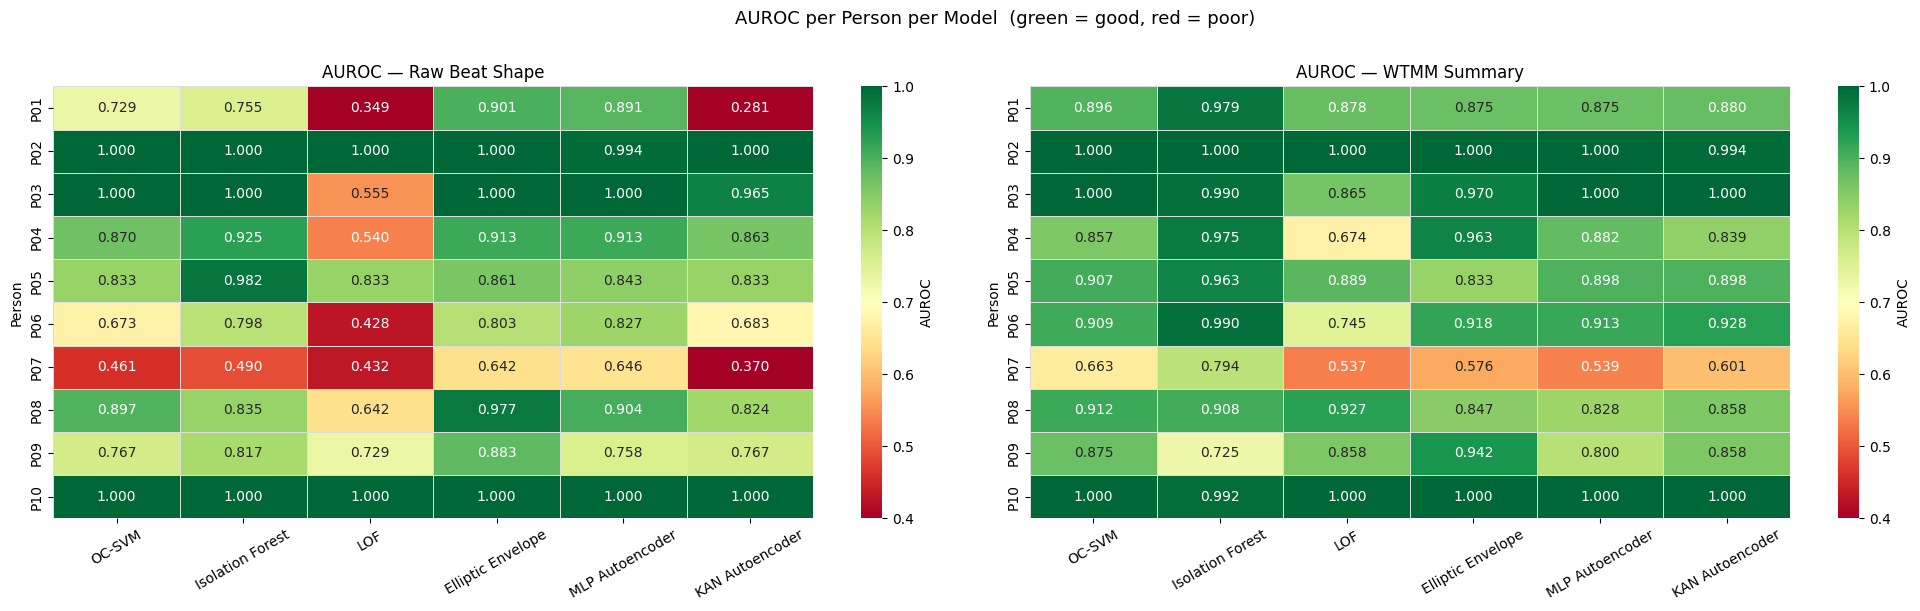

In [12]:
def to_df(res_dict, metric):
    rows = [{'Person': f'P{i+1:02d}', **{m: round(v.get(metric, np.nan), 4)
             for m, v in res.items()}} for i, res in sorted(res_dict.items())]
    df = pd.DataFrame(rows).set_index('Person')
    df.loc['MEAN'] = df.mean(numeric_only=True).round(4)
    return df


fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, (label, res) in zip(axes, [('Raw Beat Shape', raw_results),
                                     ('WTMM Summary',   wtmm_results)]):
    df = to_df(res, 'auroc').drop(index='MEAN').astype(float)
    sns.heatmap(df, ax=ax, annot=True, fmt='.3f', cmap='RdYlGn',
                vmin=0.4, vmax=1.0, linewidths=0.4, linecolor='#ddd',
                cbar_kws={'label': 'AUROC'})
    ax.set_title(f'AUROC — {label}', fontsize=12)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('AUROC per Person per Model  (green = good, red = poor)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/auroc_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

### Average performance across all people

These bars show how each model performs on average. Orange bars are the KAN; blue bars are all other models. For AUROC and F1, taller is better. For EER, shorter is better.

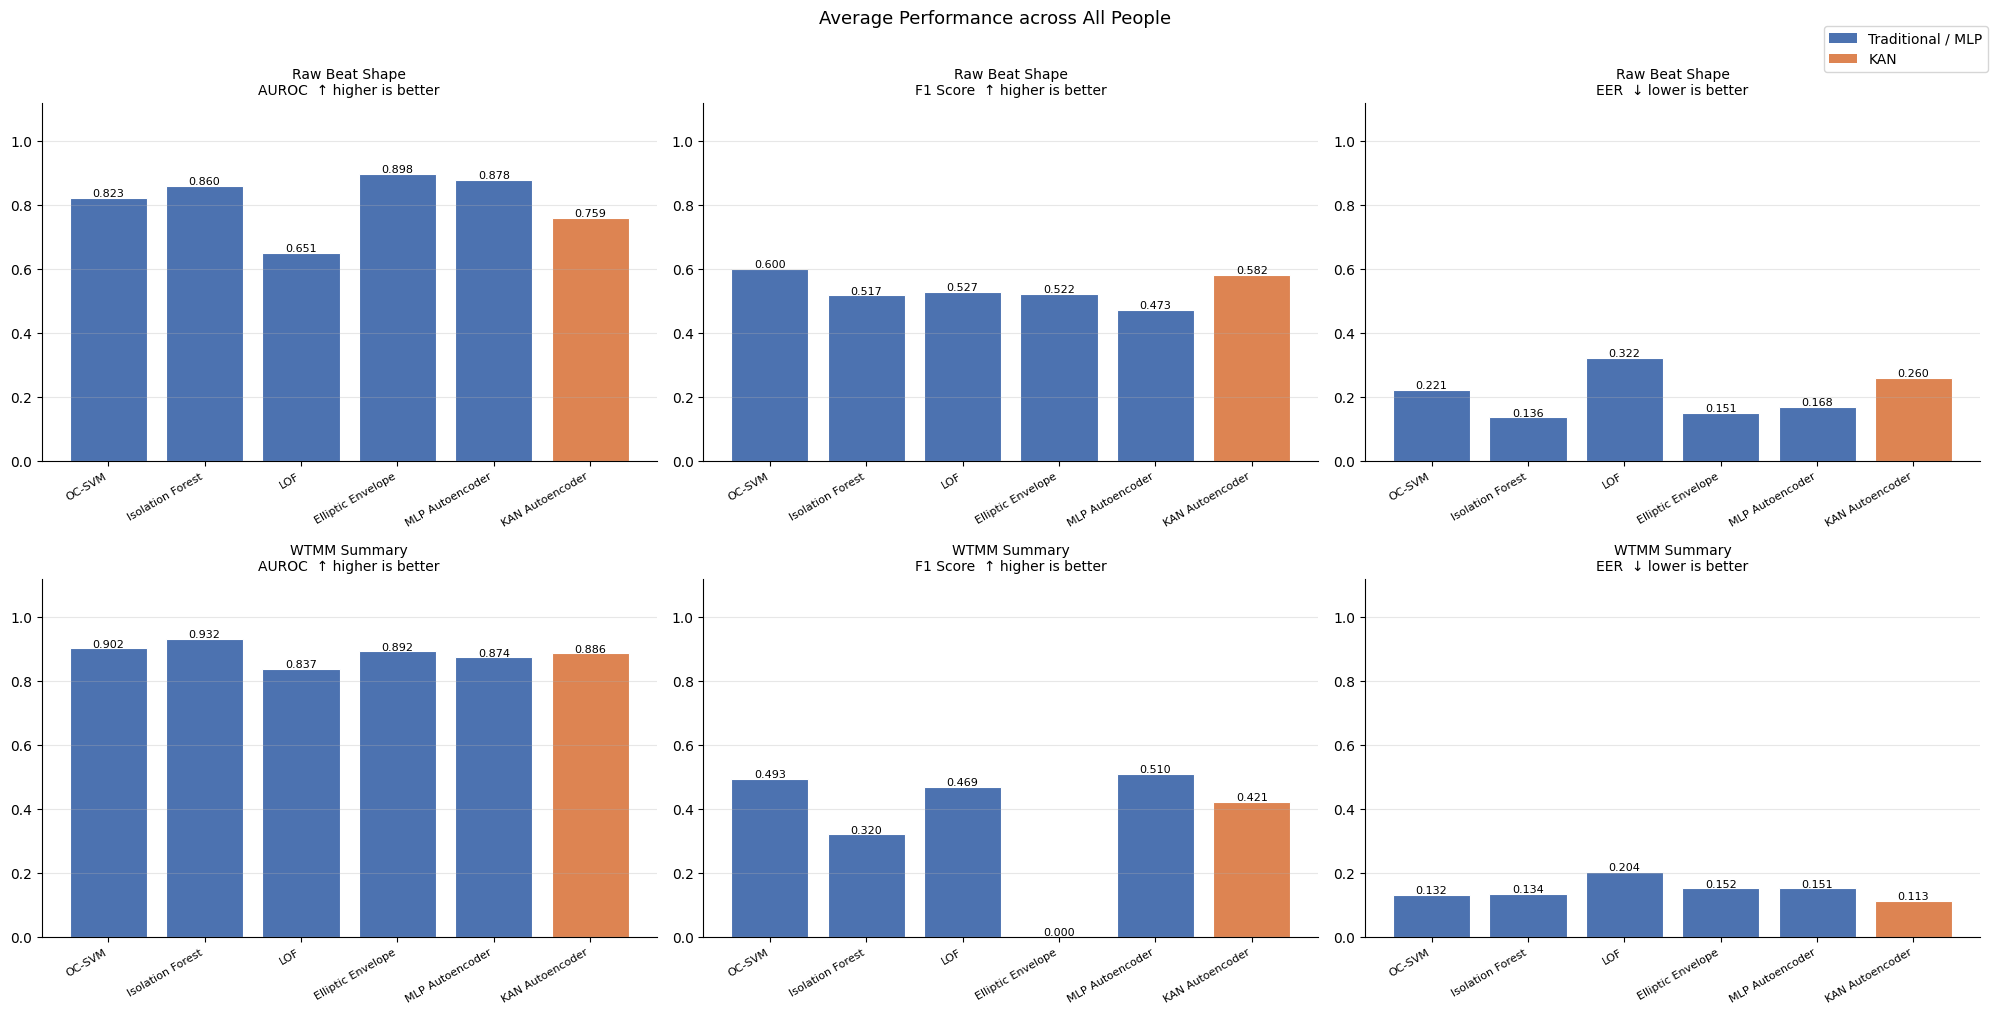

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
metric_info = [('auroc', 'AUROC  ↑ higher is better'),
               ('f1',    'F1 Score  ↑ higher is better'),
               ('eer',   'EER  ↓ lower is better')]

for row, (label, res) in enumerate([('Raw Beat Shape', raw_results),
                                      ('WTMM Summary',   wtmm_results)]):
    for col, (metric, mlabel) in enumerate(metric_info):
        ax    = axes[row, col]
        means = to_df(res, metric).loc['MEAN']
        colors= ['#DD8452' if 'KAN' in n else '#4C72B0' for n in means.index]
        bars  = ax.bar(means.index, means.values, color=colors, edgecolor='white', lw=0.8)
        for b, v in zip(bars, means.values):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                    f'{v:.3f}', ha='center', fontsize=8)
        ax.set_title(f'{label}\n{mlabel}', fontsize=10)
        ax.set_xticks(np.arange(len(means.index)))
        ax.set_xticklabels(means.index, rotation=30, ha='right', fontsize=8)
        ax.set_ylim(0, 1.12); ax.grid(axis='y', alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)

fig.legend(handles=[Patch(facecolor='#4C72B0', label='Traditional / MLP'),
                    Patch(facecolor='#DD8452', label='KAN')],
           loc='upper right', bbox_to_anchor=(1.0, 1.0))
plt.suptitle('Average Performance across All People', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/mean_performance.png', dpi=200, bbox_inches='tight')
plt.show()

### Per-person breakdown — best traditional model vs MLP vs KAN

This chart shows the three most interesting models side by side for every person. Some people are easy to identify (all models score high); others are harder and the differences between models become more visible.

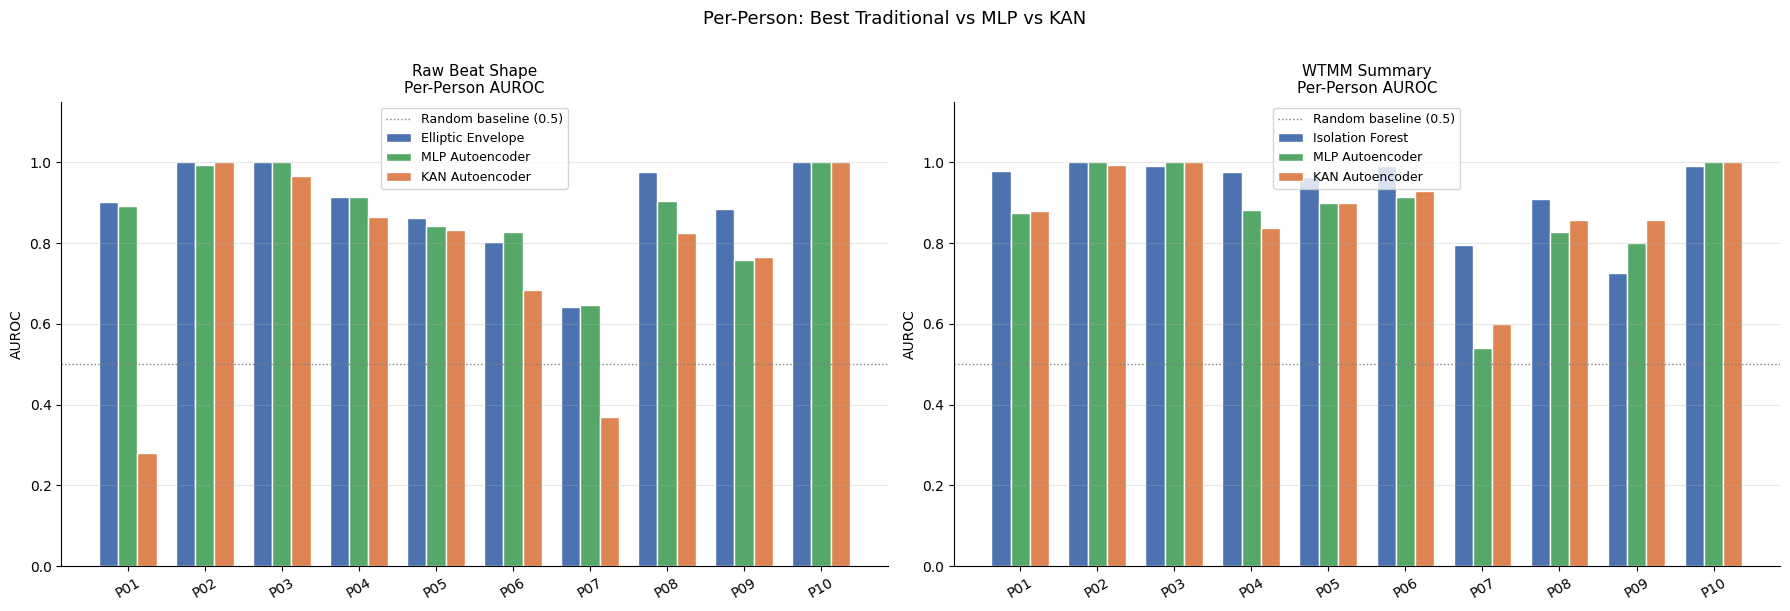

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (label, res) in zip(axes, [('Raw Beat Shape', raw_results),
                                     ('WTMM Summary',   wtmm_results)]):
    df   = to_df(res, 'auroc').drop(index='MEAN')
    trad = [c for c in df.columns if 'KAN' not in c and 'MLP' not in c]
    best = df[trad].mean().idxmax()
    x, w = np.arange(len(df)), 0.25
    ax.bar(x - w, df[best].values,                width=w, label=best,               color='#4C72B0', edgecolor='white')
    ax.bar(x,     df['MLP Autoencoder'].values,   width=w, label='MLP Autoencoder',  color='#55A868', edgecolor='white')
    ax.bar(x + w, df['KAN Autoencoder'].values,   width=w, label='KAN Autoencoder',  color='#DD8452', edgecolor='white')
    ax.set_xticks(x); ax.set_xticklabels(df.index, rotation=30)
    ax.set_ylim(0, 1.15)
    ax.axhline(0.5, ls=':', lw=1, color='gray', label='Random baseline (0.5)')
    ax.set_title(f'{label}\nPer-Person AUROC', fontsize=11)
    ax.set_ylabel('AUROC'); ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3); ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Per-Person: Best Traditional vs MLP vs KAN', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/per_person_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

---
## Step 8 — Final Summary

The table below collects the mean AUROC, F1, and EER for every model and feature combination. The last two lines highlight the best-performing model overall for each feature type.

In [15]:
print('=' * 65)
print('FINAL SUMMARY — Average metrics across all people')
print('=' * 65)

rows = []
for feat_label, res in [('Raw Beat Shape', raw_results), ('WTMM Summary', wtmm_results)]:
    for metric in ['auroc', 'f1', 'eer']:
        for model, val in to_df(res, metric).loc['MEAN'].items():
            rows.append({'Feature set': feat_label, 'Model': model,
                         'Metric': metric.upper(), 'Value': round(val, 4)})

summary = (pd.DataFrame(rows)
             .pivot_table(index=['Feature set', 'Model'], columns='Metric', values='Value'))
print(summary.to_string())
summary.to_csv(f'{OUT_DIR}/final_summary.csv')

print('\n── Best model per feature set (by AUROC) ──')
for feat_label, res in [('Raw Beat Shape', raw_results), ('WTMM Summary', wtmm_results)]:
    means = to_df(res, 'auroc').loc['MEAN']
    best  = means.idxmax()
    print(f'  {feat_label:16s} →  {best:25s}  AUROC = {means[best]:.4f}')

print(f'\nAll plots and the summary table have been saved to: {OUT_DIR}/')

FINAL SUMMARY — Average metrics across all people
Metric                             AUROC     EER      F1
Feature set    Model                                    
Raw Beat Shape Elliptic Envelope  0.8980  0.1506  0.5217
               Isolation Forest   0.8602  0.1358  0.5171
               KAN Autoencoder    0.7587  0.2601  0.5819
               LOF                0.6509  0.3224  0.5274
               MLP Autoencoder    0.8776  0.1683  0.4726
               OC-SVM             0.8229  0.2210  0.5996
WTMM Summary   Elliptic Envelope  0.8924  0.1519  0.0000
               Isolation Forest   0.9317  0.1336  0.3201
               KAN Autoencoder    0.8856  0.1128  0.4215
               LOF                0.8373  0.2036  0.4685
               MLP Autoencoder    0.8735  0.1509  0.5100
               OC-SVM             0.9018  0.1319  0.4930

── Best model per feature set (by AUROC) ──
  Raw Beat Shape   →  Elliptic Envelope          AUROC = 0.8980
  WTMM Summary     →  Isolation Forest     